# Análisis accionario

Consultado la guía diaria de Scotiabank de las fechas 21, 22, 25, 26, y 27 de mayo del 2026 así como la página de S&P Global enfocada en la BMV podremos conjeturar que nuestras mejores opciones para poder crear nuestro portafolio de inversión son las siguientes:

# Cuadro de acciones

| Código de acción | Empresa |
|---|---|
| GFNORTEO.MX | Grupo Financiero Banorte, S.A.B. de C.V. |
| GMEXICOB.MX | Grupo México, S.A.B. de C.V. |
| BIMBOA.MX | Grupo Bimbo, S.A.B. de C.V. |
| FEMSAUBD.MX | Fomento Económico Mexicano, S.A.B. de C.V. |
| CEMEXCPO.MX | CEMEX, S.A.B. de C.V. |
| GAPB.MX | Grupo Aeroportuario del Pacífico, S.A.B. de C.V. |
| ASURB.MX | Grupo Aeroportuario del Sureste, S.A.B. de C.V. |
| OMAB.MX | Grupo Aeroportuario del Centro Norte, S.A.B. de C.V. |
| MEGACPO.MX | Megacable Holdings, S.A.B. de C.V. |
| TLEVISACPO.MX | Grupo Televisa, S.A.B. |
| GENTERA.MX | Gentera, S.A.B. de C.V. |
| RA.MX | Regional, S.A.B. de C.V. |
| BOLSAA.MX | Bolsa Mexicana de Valores, S.A.B. de C.V. |
| Q.MX | Quálitas Controladora, S.A.B. de C.V. |
| KIMBERA.MX | Kimberly-Clark de México, S.A.B. de C.V. |
| LIVEPOLC-1.MX | El Puerto de Liverpool, S.A.B. de C.V. |
| LABB.MX | Genomma Lab Internacional, S.A.B. de C.V. |
| VOLARA.MX | Controladora Vuela Compañía de Aviación, S.A.B. de C.V. |
| ALSEA.MX | Alsea, S.A.B. de C.V. |
| PE&OLES.MX | Industrias Peñoles, S.A.B. de C.V. |
| GRUMAB.MX | Gruma, S.A.B. de C.V. |
| GCARSOA1.MX | Grupo Carso, S.A.B. de C.V. |
| CHDRAUIB.MX | Grupo Comercial Chedraui, S.A.B. de C.V. |
| GFINBURO.MX | Grupo Financiero Inbursa, S.A.B. de C.V. |
| SIGMAFA.MX | Sigma Foods, S.A.B. de C.V. |
| KOFUBL.MX | Coca-Cola FEMSA, S.A.B. de C.V. |
| AC.MX | Arca Continental, S.A.B. de C.V. |
| GCC.MX | GCC, S.A.B. de C.V. |
| PINFRA.MX | Promotora y Operadora de Infraestructura, S.A.B. de C.V. |
| ORBIA.MX | Orbia Advance Corporation, S.A.B. de C.V. |
| LACOMERUBC.MX | La Comer, S.A.B. de C.V. |
| VESTA.MX | Corporación Inmobiliaria Vesta, S.A.B. de C.V. |
| AMXB.MX | América Móvil, S.A.B. de C.V. |
| BBAJIOO.MX | Banco del Bajío, S.A. |
| WALMEX.MX | Wal-Mart de México, S.A.B. de C.V. |
| AZTECACPO.MX | TV Azteca, S.A.B. de C.V. |
| CUERVO.MX | Becle, S.A.B. de C.V. |
| ALPEKA.MX | Alpek, S.A.B. de C.V. |
| NEMAKA.MX | Nemak, S.A.B. de C.V. |
| HERDEZ.MX | Grupo Herdez, S.A.B. de C.V. |
| AGUA.MX | Grupo Rotoplas, S.A.B. de C.V. |
| FRAGUAB.MX | Corporativo Fragua, S.A.B. de C.V. |
| SORIANAB.MX | Organización Soriana, S.A.B. de C.V. |
| ARA.MX | Consorcio ARA, S.A.B. de C.V. |
| VITROA.MX | Vitro, S.A.B. de C.V. |
| AUTLANB.MX | Compañía Minera Autlán, S.A.B. de C.V. |
| ICHB.MX | Industrias CH, S.A.B. de C.V. |
| CYDSASAA.MX | CYDSA, S.A.B. de C.V. |

NOTA: Para poder conseguir la serie historica de las acciones usaremos de recurso el codigo en Colab proporcionado en el classroom y el cual nos genera un acrhivo llamado "SERIE_ACCIONES_IPC_TLR.xlsx" y el cual cargaremos para poder trabajar

In [65]:
#Librerias que vamos a utilizar
import pandas as pd
import yfinance as yf
import time
from scipy.stats import jarque_bera
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
from scipy.optimize import minimize



# Cargamos el archivo proporcionado por el Colab para las acciones
df = pd.read_excel(
    r"C:\Users\PC\Downloads\SERIE_ACCIONES_IPC_TLR.xlsx",
    index_col=0
)

# Preparamos los datos para que el índice sea de tipo fecha
# y esté ordenado de más antiguo a más reciente
df.index = pd.to_datetime(df.index)
df.index.name = "Fecha"
df = df.sort_index(ascending=True)

# Creamos el DataFrame donde se guardarán los rendimientos diarios
rendimientos = pd.DataFrame(index=df.index)

# Calculamos rendimientos diarios para acciones e IPC
for columna in df.columns:

    if columna != "RF_BONO_M10":

        precio_hoy = df[columna]
        precio_ayer = df[columna].shift(1)

        rendimientos[columna] = (precio_hoy / precio_ayer) - 1

# Calculamos el rendimiento diario equivalente del BONO_M10
rendimientos["RF_BONO_M10"] = (1 + df["RF_BONO_M10"]) ** (1 / 252) - 1

# Eliminamos filas donde todos los valores sean NaN
rendimientos = rendimientos.dropna(how="all")

# Convertimos los rendimientos a porcentaje
rendimientos = rendimientos * 100

# Visualizamos el resultado
rendimientos.head()

,GFNORTEO.MX,GMEXICOB.MX,BIMBOA.MX,FEMSAUBD.MX,CEMEXCPO.MX,GAPB.MX,ASURB.MX,OMAB.MX,MEGACPO.MX,TLEVISACPO.MX,...,AGUA.MX,FRAGUAB.MX,SORIANAB.MX,ARA.MX,VITROA.MX,AUTLANB.MX,ICHB.MX,CYDSASAA.MX,IPC,RF_BONO_M10
Fecha,,,,,,,,,,,,,,,,,,,,,
2025-05-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.036527
2025-05-23,1.254820,1.704705,0.973678,0.332644,1.920237,2.057540,1.801367,-0.645899,-3.603962,-1.501878,...,-2.686564,0.290446,-0.581821,-1.492530,0.000000,0.589970,0.586758,0.0,0.890496,0.036494
2025-05-26,-0.351602,0.574715,-0.035715,-1.228606,1.376807,3.101447,1.498529,-1.439065,0.504085,0.762389,...,0.843557,2.042803,0.000000,0.909088,-0.944889,0.733134,0.000000,0.0,0.083528,0.036546
2025-05-27,1.457655,0.961908,-0.911041,1.826340,-0.857759,-4.502241,-1.827436,0.511247,1.776391,-1.387129,...,-1.520908,0.000000,-3.438189,-2.702702,-4.610488,-5.385734,0.000000,0.0,0.230362,0.036693
2025-05-28,0.570119,1.160258,-0.685056,0.281161,-0.720977,2.510374,1.034745,1.081946,5.030806,-0.255755,...,0.849419,0.952379,0.189399,0.000000,4.666670,-0.769234,0.000000,0.0,0.242400,0.036650


## Cálculo de rendimientos

Como vimos para calcular los rendimientos utilizamos la siguiente fórmula:

$$
R_t = \frac{P_t}{P_{t-1}} - 1
$$

Donde:
- $R_t$ = Rendimiento en el día $t$
- $P_t$ = Precio de hoy
- $P_{t-1}$ = Precio de ayer

### Estadísticas descriptivas

A continuación calculamos las siguientes estadísticas:
- Media
- Desviación estándar
- Varianza
- Kurtosis
- Máximos y mínimos
- Rango

### Prueba de normalidad

Finalmente aplicamos la **Prueba de Jarque Bera** para verificar si los datos cumplen con el criterio de normalidad, obteniendo los siguientes resultados:

In [66]:

# Estadísticas descriptivas
estadisticas_A1 = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Desviacion_Estandar": rendimientos.std(),
    "Varianza": rendimientos.var() ,
    "Kurtosis": rendimientos.kurt(),
    "Skewness": rendimientos.skew(),
    "Minimo": rendimientos.min(),
    "Maximo": rendimientos.max()
})

# Calculamos el rango: máximo - mínimo
estadisticas_A1["Rango"] = estadisticas_A1["Maximo"] - estadisticas_A1["Minimo"]

#Aplicamos la prueba de Jarque-Bera para cada acción 
alpha = 0.05 #para obtener un nivel de confianza del 95%
jarque_bera_resultados = []
p_values = []
decisiones_jb = []
conclusiones_jb = []

for accion in estadisticas_A1.index:
    
    serie = rendimientos[accion].dropna()
    jb_stat, p_value = jarque_bera(serie)
    
    jarque_bera_resultados.append(jb_stat)
    p_values.append(p_value)
    
    if p_value < alpha:
        decisiones_jb.append("Se rechaza H0")
        conclusiones_jb.append("No normal")
    else:
        decisiones_jb.append("No se rechaza H0")
        conclusiones_jb.append("Normal")

estadisticas_A1["Jarque_Bera"] = jarque_bera_resultados
estadisticas_A1["P_value_JB"] = p_values
estadisticas_A1["Decision_JB"] = decisiones_jb
estadisticas_A1["Conclusion_JB"] = conclusiones_jb
#reordemos las columnas para que se vean de una mejor manera
estadisticas_A1 = estadisticas_A1[
    [
        "Media",
        "Desviacion_Estandar",
        "Varianza",
        "Kurtosis",
        "Skewness",
        "Rango",
        "Maximo",
        "Minimo",
        "Jarque_Bera",
        "P_value_JB",
        "Decision_JB",
        "Conclusion_JB"
    ]
]

# Ordenar de mayor a menor (ascending=False)
estadisticas_A1 = estadisticas_A1.sort_values('Media', ascending=False)
#finalmente obtenemos los siguientes resultados:
estadisticas_A1

,Media,Desviacion_Estandar,Varianza,Kurtosis,Skewness,Rango,Maximo,Minimo,Jarque_Bera,P_value_JB,Decision_JB,Conclusion_JB
PE&OLES.MX,0.408314,3.356718,11.267553,1.418218,0.147165,23.848666,10.430602,-13.418064,20.244412,4.017740e-05,Se rechaza H0,No normal
GMEXICOB.MX,0.315325,2.434892,5.928699,6.428997,-1.041280,23.374718,8.385619,-14.989099,453.189227,3.901304e-99,Se rechaza H0,No normal
ORBIA.MX,0.240692,2.650232,7.023732,16.607624,1.898443,31.184265,21.415031,-9.769234,2888.095282,0.000000e+00,Se rechaza H0,No normal
CYDSASAA.MX,0.236389,1.802950,3.250628,36.281092,3.890965,22.538358,17.672599,-4.865759,13719.882892,0.000000e+00,Se rechaza H0,No normal
CEMEXCPO.MX,0.214580,2.052619,4.213244,3.292459,0.918458,15.449202,10.683012,-4.766190,141.007133,2.402648e-31,Se rechaza H0,No normal
VOLARA.MX,0.192728,3.080411,9.488935,3.091323,0.812480,22.794299,14.765106,-8.029193,120.789214,5.901404e-27,Se rechaza H0,No normal
ARA.MX,0.175467,1.946153,3.787510,1.237404,0.166134,14.703647,6.990882,-7.712765,15.791483,3.723258e-04,Se rechaza H0,No normal
VITROA.MX,0.164513,3.537311,12.512566,178.005446,12.268853,56.990353,51.329971,-5.660382,321828.977867,0.000000e+00,Se rechaza H0,No normal
HERDEZ.MX,0.158170,2.740119,7.508255,69.569220,6.325570,39.950084,31.364376,-8.585707,49835.034925,0.000000e+00,Se rechaza H0,No normal
AMXB.MX,0.144346,1.479650,2.189364,2.093289,0.767242,10.336433,6.608361,-3.728072,66.784182,3.147743e-15,Se rechaza H0,No normal


In [67]:
#este codigo es para visualización de las acciones
celdas_amarillas = [
    ("GAPB.MX", "Conclusion_JB"),
    ("ASURB.MX", "Conclusion_JB"),
    ("GENTERA.MX", "Conclusion_JB"),
    ("GCARSOA1.MX", "Conclusion_JB")
]

celdas_azules = [
    ("BOLSAA.MX", "Media"),
    ("Q.MX", "Media"),
    ("LABB.MX", "Media"),
    ("GRUMAB.MX", "Media"),
    ("CHDRAUIB.MX", "Media"),
    ("GFINBURO.MX", "Media"),
    ("LACOMERUBC.MX", "Media"),
    ("WALMEX.MX", "Media"),
    ("CUERVO.MX", "Media"),
    ("ASURB.MX", "Media")
]

def resaltar_celdas(df):
    estilos = pd.DataFrame("", index=df.index, columns=df.columns)

    # Celdas amarillas
    for fila, columna in celdas_amarillas:
        if fila in df.index and columna in df.columns:
            estilos.loc[fila, columna] = "background-color: yellow; font-weight: bold"

    # Celdas azules
    for fila, columna in celdas_azules:
        if fila in df.index and columna in df.columns:
            estilos.loc[fila, columna] = "background-color: lightblue; font-weight: bold"

    return estilos
estadisticas_A1_estilizado = estadisticas_A1.style.apply(
    resaltar_celdas,
    axis=None
)

display(estadisticas_A1_estilizado)

,Media,Desviacion_Estandar,Varianza,Kurtosis,Skewness,Rango,Maximo,Minimo,Jarque_Bera,P_value_JB,Decision_JB,Conclusion_JB
PE&OLES.MX,0.408314,3.356718,11.267553,1.418218,0.147165,23.848666,10.430602,-13.418064,20.244412,0.000040,Se rechaza H0,No normal
GMEXICOB.MX,0.315325,2.434892,5.928699,6.428997,-1.041280,23.374718,8.385619,-14.989099,453.189227,0.000000,Se rechaza H0,No normal
ORBIA.MX,0.240692,2.650232,7.023732,16.607624,1.898443,31.184265,21.415031,-9.769234,2888.095282,0.000000,Se rechaza H0,No normal
CYDSASAA.MX,0.236389,1.802950,3.250628,36.281092,3.890965,22.538358,17.672599,-4.865759,13719.882892,0.000000,Se rechaza H0,No normal
CEMEXCPO.MX,0.214580,2.052619,4.213244,3.292459,0.918458,15.449202,10.683012,-4.766190,141.007133,0.000000,Se rechaza H0,No normal
VOLARA.MX,0.192728,3.080411,9.488935,3.091323,0.812480,22.794299,14.765106,-8.029193,120.789214,0.000000,Se rechaza H0,No normal
ARA.MX,0.175467,1.946153,3.787510,1.237404,0.166134,14.703647,6.990882,-7.712765,15.791483,0.000372,Se rechaza H0,No normal
VITROA.MX,0.164513,3.537311,12.512566,178.005446,12.268853,56.990353,51.329971,-5.660382,321828.977867,0.000000,Se rechaza H0,No normal
HERDEZ.MX,0.158170,2.740119,7.508255,69.569220,6.325570,39.950084,31.364376,-8.585707,49835.034925,0.000000,Se rechaza H0,No normal
AMXB.MX,0.144346,1.479650,2.189364,2.093289,0.767242,10.336433,6.608361,-3.728072,66.784182,0.000000,Se rechaza H0,No normal


## Resultados de la prueba de normalidad (JB)

Después de aplicar la prueba de Jarque Bera (JB), las siguientes acciones **sí cumplen** con el criterio de normalidad:

- **GENTERA**
- **GCARSOA**
- **GAPB**
- **ASURB**

## Primer filtrado: rendimiento negativo

Para realizar un primer filtrado, quitaremos aquellas acciones que tienen un **rendimiento negativo**:

| Acciones con rendimiento negativo |
|-----------------------------------|
| LACOMERUBC |
| ASURB |
| BOLSAA |
| GFINBURO |
| Q |
| WALMEX |
| GRUMAB |
| LABB |
| CHDRAUIB |
| CUERVO |

## Punto importante

Sin embargo, mantendremos **ASURB**, ya que cumple con el supuesto de normalidad y trataremos de evaluar si es conveniente conservarlo para que nuestro modelo sea mejor.

In [68]:
# Lista de índices a eliminar
indices_a_eliminar = ['BOLSAA.MX', 'Q.MX', 'LABB.MX', 'GRUMAB.MX', 
                      'CHDRAUIB.MX', 'GFINBURO.MX', 'LACOMERUBC.MX', 
                      'WALMEX.MX', 'CUERVO.MX']
estadisticas_A1 = estadisticas_A1.drop(indices_a_eliminar, errors='ignore')

# este codigo es para visualización de las acciones
# Celdas verdes (Media)
tickers_verdes = ['AZTECACPO.MX', 'ASURB.MX', 'OMAB.MX', 'RA.MX', 'FRAGUAB.MX','GAPB.MX']
celdas_verdes = [(ticker, "Media") for ticker in tickers_verdes]

# Celdas rojas (Desviacion_Estandar)
tickers_rojos = ['AZTECACPO.MX', 'ASURB.MX', 'OMAB.MX', 'RA.MX', 'FRAGUAB.MX','GAPB.MX']
celdas_rojas = [(ticker, "Desviacion_Estandar") for ticker in tickers_rojos]

def resaltar_celdas(df):
    estilos = pd.DataFrame("", index=df.index, columns=df.columns)

    # Celdas verdes (Media)
    for fila, columna in celdas_verdes:
        if fila in df.index and columna in df.columns:
            estilos.loc[fila, columna] = "background-color: lightgreen; font-weight: bold"

    # Celdas rojas (Desviacion_Estandar)
    for fila, columna in celdas_rojas:
        if fila in df.index and columna in df.columns:
            estilos.loc[fila, columna] = "background-color: #ffcccc; font-weight: bold"  # Rojo claro

    return estilos
estadisticas_A1_estilizado = estadisticas_A1.style.apply(
    resaltar_celdas,
    axis=None
)

display(estadisticas_A1_estilizado)

,Media,Desviacion_Estandar,Varianza,Kurtosis,Skewness,Rango,Maximo,Minimo,Jarque_Bera,P_value_JB,Decision_JB,Conclusion_JB
PE&OLES.MX,0.408314,3.356718,11.267553,1.418218,0.147165,23.848666,10.430602,-13.418064,20.244412,0.000040,Se rechaza H0,No normal
GMEXICOB.MX,0.315325,2.434892,5.928699,6.428997,-1.041280,23.374718,8.385619,-14.989099,453.189227,0.000000,Se rechaza H0,No normal
ORBIA.MX,0.240692,2.650232,7.023732,16.607624,1.898443,31.184265,21.415031,-9.769234,2888.095282,0.000000,Se rechaza H0,No normal
CYDSASAA.MX,0.236389,1.802950,3.250628,36.281092,3.890965,22.538358,17.672599,-4.865759,13719.882892,0.000000,Se rechaza H0,No normal
CEMEXCPO.MX,0.214580,2.052619,4.213244,3.292459,0.918458,15.449202,10.683012,-4.766190,141.007133,0.000000,Se rechaza H0,No normal
VOLARA.MX,0.192728,3.080411,9.488935,3.091323,0.812480,22.794299,14.765106,-8.029193,120.789214,0.000000,Se rechaza H0,No normal
ARA.MX,0.175467,1.946153,3.787510,1.237404,0.166134,14.703647,6.990882,-7.712765,15.791483,0.000372,Se rechaza H0,No normal
VITROA.MX,0.164513,3.537311,12.512566,178.005446,12.268853,56.990353,51.329971,-5.660382,321828.977867,0.000000,Se rechaza H0,No normal
HERDEZ.MX,0.158170,2.740119,7.508255,69.569220,6.325570,39.950084,31.364376,-8.585707,49835.034925,0.000000,Se rechaza H0,No normal
AMXB.MX,0.144346,1.479650,2.189364,2.093289,0.767242,10.336433,6.608361,-3.728072,66.784182,0.000000,Se rechaza H0,No normal


## Siguiente paso: rendimiento bajo y alta volatilidad

Como siguiente paso veremos quién tiene un **rendimiento bajo** y **alta volatilidad**. Ese sería el caso de las siguientes acciones:

- **FRAGUAB**
- **OMAB**
- **RA**
- **GAPB**
## Decisiones de filtrado

Sin embargo, para este caso, por la cuestión de la volatilidad, es conveniente quitar **ASURB**.

Además, dado que **AZTECACPO** cumple con el criterio de baja actividad, también la quitaremos.

In [69]:
# Índices a eliminar
indices_a_eliminar = ['AZTECACPO.MX', 'ASURB.MX', 'OMAB.MX', 'RA.MX', 'FRAGUAB.MX','GAPB.MX']

# Eliminar los renglones
estadisticas_A1 = estadisticas_A1.drop(indices_a_eliminar, errors='ignore')

In [70]:
# este codigo es para visualización de las acciones
colores_config = {
    '#ffa500': [  # Naranja
        ("VITROA.MX", "Kurtosis"),
        ("HERDEZ.MX", "Kurtosis")
    ],
    '#8b4513': [  # Café
        ("AGUA.MX", "Media"),
        ("AGUA.MX", "Rango")
    ]
}

def resaltar_celdas(df):
    estilos = pd.DataFrame("", index=df.index, columns=df.columns)
    
    for color, celdas in colores_config.items():
        for fila, columna in celdas:
            if fila in df.index and columna in df.columns:
                if color == '#8b4513':  # Café con texto blanco
                    estilos.loc[fila, columna] = f"background-color: {color}; font-weight: bold; color: white"
                else:  # Naranja
                    estilos.loc[fila, columna] = f"background-color: {color}; font-weight: bold"
    
    return estilos

estadisticas_A1_estilizado = estadisticas_A1.style.apply(resaltar_celdas, axis=None)
display(estadisticas_A1_estilizado)

,Media,Desviacion_Estandar,Varianza,Kurtosis,Skewness,Rango,Maximo,Minimo,Jarque_Bera,P_value_JB,Decision_JB,Conclusion_JB
PE&OLES.MX,0.408314,3.356718,11.267553,1.418218,0.147165,23.848666,10.430602,-13.418064,20.244412,0.000040,Se rechaza H0,No normal
GMEXICOB.MX,0.315325,2.434892,5.928699,6.428997,-1.041280,23.374718,8.385619,-14.989099,453.189227,0.000000,Se rechaza H0,No normal
ORBIA.MX,0.240692,2.650232,7.023732,16.607624,1.898443,31.184265,21.415031,-9.769234,2888.095282,0.000000,Se rechaza H0,No normal
CYDSASAA.MX,0.236389,1.802950,3.250628,36.281092,3.890965,22.538358,17.672599,-4.865759,13719.882892,0.000000,Se rechaza H0,No normal
CEMEXCPO.MX,0.214580,2.052619,4.213244,3.292459,0.918458,15.449202,10.683012,-4.766190,141.007133,0.000000,Se rechaza H0,No normal
VOLARA.MX,0.192728,3.080411,9.488935,3.091323,0.812480,22.794299,14.765106,-8.029193,120.789214,0.000000,Se rechaza H0,No normal
ARA.MX,0.175467,1.946153,3.787510,1.237404,0.166134,14.703647,6.990882,-7.712765,15.791483,0.000372,Se rechaza H0,No normal
VITROA.MX,0.164513,3.537311,12.512566,178.005446,12.268853,56.990353,51.329971,-5.660382,321828.977867,0.000000,Se rechaza H0,No normal
HERDEZ.MX,0.158170,2.740119,7.508255,69.569220,6.325570,39.950084,31.364376,-8.585707,49835.034925,0.000000,Se rechaza H0,No normal
AMXB.MX,0.144346,1.479650,2.189364,2.093289,0.767242,10.336433,6.608361,-3.728072,66.784182,0.000000,Se rechaza H0,No normal


## Acciones a eliminar

Dado que las acciones **VITROA** y **HERDEZ** tienen una kurtosis muy elevada, vamos a eliminarlas.

Asimismo, eliminaremos **AGUA**, ya que su rango elevado no compensa la poca ganancia que nos ofrece, lo que implica un mayor riesgo que, podría decirse, no es compensado.

In [71]:
# Índices a eliminar
indices_a_eliminar = ['AGUA.MX', 'VITROA.MX', 'HERDEZ.MX']

# Eliminar los renglones
estadisticas_A1 = estadisticas_A1.drop(indices_a_eliminar, errors='ignore')
estadisticas_A1 
#este codigo es para visualización de las acciones
indices_rosa = ['ICHB.MX', 'VESTA.MX', 'NEMAKA.MX', 'KOFUBL.MX', 
                'BIMBOA.MX', 'AUTLANB.MX', 'ALPEKA.MX', 'SORIANAB.MX']

def resaltar_filas(df):
    # Crear un DataFrame de estilos vacío
    estilos = pd.DataFrame("", index=df.index, columns=df.columns)
    
    # Colorear filas completas de rosa claro
    for idx in indices_rosa:
        if idx in df.index:
            estilos.loc[idx, :] = "background-color: #ffcccc"  # Rosa claro
    
    return estilos
estadisticas_A1_estilizado = estadisticas_A1.style.apply(resaltar_filas, axis=None)

display(estadisticas_A1_estilizado)

,Media,Desviacion_Estandar,Varianza,Kurtosis,Skewness,Rango,Maximo,Minimo,Jarque_Bera,P_value_JB,Decision_JB,Conclusion_JB
PE&OLES.MX,0.408314,3.356718,11.267553,1.418218,0.147165,23.848666,10.430602,-13.418064,20.244412,0.000040,Se rechaza H0,No normal
GMEXICOB.MX,0.315325,2.434892,5.928699,6.428997,-1.041280,23.374718,8.385619,-14.989099,453.189227,0.000000,Se rechaza H0,No normal
ORBIA.MX,0.240692,2.650232,7.023732,16.607624,1.898443,31.184265,21.415031,-9.769234,2888.095282,0.000000,Se rechaza H0,No normal
CYDSASAA.MX,0.236389,1.802950,3.250628,36.281092,3.890965,22.538358,17.672599,-4.865759,13719.882892,0.000000,Se rechaza H0,No normal
CEMEXCPO.MX,0.214580,2.052619,4.213244,3.292459,0.918458,15.449202,10.683012,-4.766190,141.007133,0.000000,Se rechaza H0,No normal
VOLARA.MX,0.192728,3.080411,9.488935,3.091323,0.812480,22.794299,14.765106,-8.029193,120.789214,0.000000,Se rechaza H0,No normal
ARA.MX,0.175467,1.946153,3.787510,1.237404,0.166134,14.703647,6.990882,-7.712765,15.791483,0.000372,Se rechaza H0,No normal
AMXB.MX,0.144346,1.479650,2.189364,2.093289,0.767242,10.336433,6.608361,-3.728072,66.784182,0.000000,Se rechaza H0,No normal
TLEVISACPO.MX,0.131242,2.699450,7.287028,4.044297,0.958591,22.761554,13.362077,-9.399477,198.695190,0.000000,Se rechaza H0,No normal
MEGACPO.MX,0.124934,2.173219,4.722882,2.129420,0.247335,16.140215,9.121864,-7.018351,46.659603,0.000000,Se rechaza H0,No normal


## Acciones a considerar
estas acciones marcadas de color rosa podriamos omitirlas por los siguientes motivos

| Acción          | Por qué?                                                                                                                                                                                            |
| --------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **ICHB.MX**     | Tiene una media baja del **0.0108%**, por lo que su rendimiento promedio diario es prácticamente nulo. Aunque su desviación estándar no es extrema, el rendimiento es muy bajo.                          |
| **VESTA.MX**    | Su media es baja, **0.0280%**, frente a una desviación estándar de **1.34%**. El rendimiento promedio es reducido respecto al riesgo asumido.                                                            |
| **NEMAKA.MX**   | Media de **0.0368%** con desviación estándar de **1.85%** y rango de **14.11%**. Presenta riesgo considerable para una media baja.                                                                       |
| **KOFUBL.MX**   | Media de **0.0406%**, desviación de **1.60%** y mínimo de **-6.56%**. El rendimiento no compensa suficientemente la variabilidad.                                                                        |
| **BIMBOA.MX**   | Media de **0.0421%**, desviación de **1.83%** y rango de **13.26%**. Tiene rendimiento positivo, pero bajo frente al riesgo.                                                                             |
| **AUTLANB.MX**  | Media de **0.0525%**, desviación de **2.01%** y rango de **13.40%**. Presenta volatilidad alta para su rendimiento promedio.                                                                             |
| **ALPEKA.MX**   | Media de **0.0638%**, pero desviación estándar de **2.39%** y rango de **16.59%**. El riesgo es elevado para la media que ofrece.                                                                        |
| **SORIANAB.MX** | Media de **0.0626%**, desviación de **2.44%** y rango de **20.16%**. Presenta un rango amplio y riesgo alto frente a su rendimiento.                                                                     |


## Resultado final del filtrado

Después de revisar los filtros anteriores que consideraron factores como:

- **Baja actividad**
- **Alta variabilidad**
- **Rendimiento negativo**
- **Riesgo no compensado**

Obtenemos como resultado las siguientes acciones:

In [72]:
# Índices a eliminar
indices_a_eliminar = ['ICHB.MX','VESTA.MX','NEMAKA.MX','KOFUBL.MX','BIMBOA.MX','AUTLANB.MX','ALPEKA.MX','SORIANAB.MX']

# Eliminar los renglones
estadisticas_A1 = estadisticas_A1.drop(indices_a_eliminar, errors='ignore')
estadisticas_A1 

#este codigo es para visualización de las acciones
colores_renglones = {
    'rojo': ['GENTERA.MX', 'GCARSOA1.MX'],
    'amarillo': ['PINFRA.MX'],
    'verde': ['AMXB.MX', 'CEMEXCPO.MX', 'LIVEPOLC-1.MX', 'FEMSAUBD.MX','ARA.MX','GCC.MX']
}

def resaltar_filas(df):
    # Crear un DataFrame de estilos vacío
    estilos = pd.DataFrame("", index=df.index, columns=df.columns)
    
    # Colorear filas de rojo
    for idx in colores_renglones['rojo']:
        if idx in df.index:
            estilos.loc[idx, :] = "background-color: #ffcccc"  # Rojo claro
    
    # Colorear filas de amarillo
    for idx in colores_renglones['amarillo']:
        if idx in df.index:
            estilos.loc[idx, :] = "background-color: #ffff99"  # Amarillo claro
    
    # Colorear filas de verde
    for idx in colores_renglones['verde']:
        if idx in df.index:
            estilos.loc[idx, :] = "background-color: #90ee90"  # Verde claro
    
    return estilos

estadisticas_A1_estilizado = estadisticas_A1.style.apply(resaltar_filas, axis=None)
display(estadisticas_A1_estilizado)

,Media,Desviacion_Estandar,Varianza,Kurtosis,Skewness,Rango,Maximo,Minimo,Jarque_Bera,P_value_JB,Decision_JB,Conclusion_JB
PE&OLES.MX,0.408314,3.356718,11.267553,1.418218,0.147165,23.848666,10.430602,-13.418064,20.244412,0.000040,Se rechaza H0,No normal
GMEXICOB.MX,0.315325,2.434892,5.928699,6.428997,-1.041280,23.374718,8.385619,-14.989099,453.189227,0.000000,Se rechaza H0,No normal
ORBIA.MX,0.240692,2.650232,7.023732,16.607624,1.898443,31.184265,21.415031,-9.769234,2888.095282,0.000000,Se rechaza H0,No normal
CYDSASAA.MX,0.236389,1.802950,3.250628,36.281092,3.890965,22.538358,17.672599,-4.865759,13719.882892,0.000000,Se rechaza H0,No normal
CEMEXCPO.MX,0.214580,2.052619,4.213244,3.292459,0.918458,15.449202,10.683012,-4.766190,141.007133,0.000000,Se rechaza H0,No normal
VOLARA.MX,0.192728,3.080411,9.488935,3.091323,0.812480,22.794299,14.765106,-8.029193,120.789214,0.000000,Se rechaza H0,No normal
ARA.MX,0.175467,1.946153,3.787510,1.237404,0.166134,14.703647,6.990882,-7.712765,15.791483,0.000372,Se rechaza H0,No normal
AMXB.MX,0.144346,1.479650,2.189364,2.093289,0.767242,10.336433,6.608361,-3.728072,66.784182,0.000000,Se rechaza H0,No normal
TLEVISACPO.MX,0.131242,2.699450,7.287028,4.044297,0.958591,22.761554,13.362077,-9.399477,198.695190,0.000000,Se rechaza H0,No normal
MEGACPO.MX,0.124934,2.173219,4.722882,2.129420,0.247335,16.140215,9.121864,-7.018351,46.659603,0.000000,Se rechaza H0,No normal


## Problemas encontrados y solución

Ahora nos encontramos con diferentes problemas:

**1.** Solamente **2 acciones** cumplen con el criterio de normalidad: **GENTERA.MX** y **GCARSOA1.MX**, que no suelen ser acciones muy atractivas por el rendimiento vs volatilidad.

**2.** Nuestras mejores alternativas son las acciones marcadas en **verde**, pero no cumplen con el criterio de normalidad.

**3.** El siguiente paso es ver las **matrices de covarianza y correlación**; sin embargo, si consideramos la matriz original de **50×50** obtendríamos como resultados totales: **2500**, que nos podría costar analizar.

**4.** Nuestra solución es usar los rendimientos de las acciones obtenidas **después del filtrado**, que nos daría como resultado una matriz de **25×25 = 625**, que es algo un poco más manejable.

In [73]:
# Definir la lista de columnas
columnas_seleccionadas = ['PE&OLES.MX', 'GMEXICOB.MX', 'ORBIA.MX', 'CYDSASAA.MX',
                           'CEMEXCPO.MX', 'VOLARA.MX', 'ARA.MX', 'AMXB.MX',
                           'TLEVISACPO.MX', 'MEGACPO.MX', 'PINFRA.MX', 'GENTERA.MX',
                           'BBAJIOO.MX', 'KIMBERA.MX', 'ALSEA.MX', 'GCC.MX',
                           'SIGMAFA.MX', 'GFNORTEO.MX',
                           'GCARSOA1.MX', 'AC.MX', 'LIVEPOLC-1.MX',
                           'FEMSAUBD.MX','IPC','RF_BONO_M10']

# Seleccionar las columnas
rendimientos_filtrado = rendimientos[columnas_seleccionadas]


El siguiente paso es obtener la matriz de varianza y covarianza, sin embargo primero veamos la relación que hay con el IPC

In [74]:
# Obtener correlación de IPC con todas las demás columnas
correlacion_IPC = rendimientos_filtrado.corr()['IPC'].sort_values(ascending=False)

# Mostrar resultados
print("=== CORRELACIÓN DE IPC CON LAS DEMÁS COLUMNAS ===\n")
print(correlacion_IPC)


=== CORRELACIÓN DE IPC CON LAS DEMÁS COLUMNAS ===

IPC              1.000000
GMEXICOB.MX      0.705586
GFNORTEO.MX      0.680210
CEMEXCPO.MX      0.610182
PINFRA.MX        0.563837
AMXB.MX          0.555461
PE&OLES.MX       0.529652
BBAJIOO.MX       0.518076
AC.MX            0.516611
GCARSOA1.MX      0.506665
GCC.MX           0.484388
FEMSAUBD.MX      0.461206
KIMBERA.MX       0.435428
MEGACPO.MX       0.408076
ALSEA.MX         0.390206
ORBIA.MX         0.363801
GENTERA.MX       0.354964
VOLARA.MX        0.347982
SIGMAFA.MX       0.209523
LIVEPOLC-1.MX    0.198873
TLEVISACPO.MX    0.170284
CYDSASAA.MX      0.009585
ARA.MX          -0.005930
RF_BONO_M10     -0.020249
Name: IPC, dtype: float64


In [75]:
# Obtener covarianza de IPC con todas las demás columnas
covarianza_IPC = rendimientos_filtrado.cov()['IPC'].sort_values(ascending=False)

# Mostrar resultados
print("=== COVARIANZA DE IPC CON LAS DEMÁS COLUMNAS ===\n")
print(covarianza_IPC)


=== COVARIANZA DE IPC CON LAS DEMÁS COLUMNAS ===

PE&OLES.MX       1.822389
GMEXICOB.MX      1.761024
CEMEXCPO.MX      1.283817
GCARSOA1.MX      1.194954
GFNORTEO.MX      1.122531
VOLARA.MX        1.098756
PINFRA.MX        1.070477
IPC              1.050682
BBAJIOO.MX       0.997171
ORBIA.MX         0.988287
MEGACPO.MX       0.909033
GCC.MX           0.861168
AMXB.MX          0.842458
GENTERA.MX       0.814500
AC.MX            0.782322
ALSEA.MX         0.751144
KIMBERA.MX       0.699262
FEMSAUBD.MX      0.659981
TLEVISACPO.MX    0.471177
SIGMAFA.MX       0.302490
LIVEPOLC-1.MX    0.266781
CYDSASAA.MX      0.017714
RF_BONO_M10     -0.000028
ARA.MX          -0.011830
Name: IPC, dtype: float64


es importante observar como algunas acciones con altos rendimientos tienen una gran correlación y covarianza con el IPC, además algunas de las acciones que empiezan a ver como las mas atractivas tambien tienen un alto valor, ahora para el siguiente paso veremos las correlaciones entre las acciones para eso omitiremos al IPC, ademas veremos el nivel que de relación que hay entre ellas con ayuda de algunos histogramas

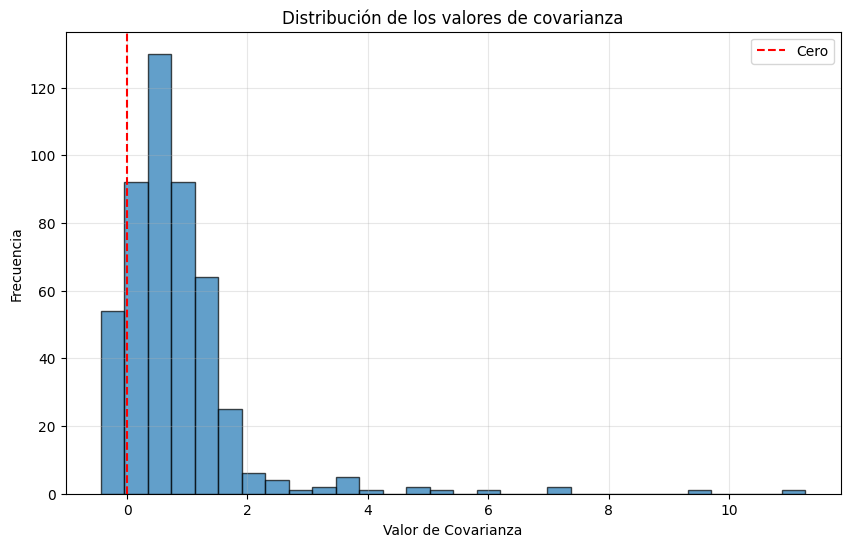

In [76]:
rendimientos_filtrado = rendimientos_filtrado.drop(columns=['IPC', 'RF_BONO_M10'])
matriz_covarianza = rendimientos_filtrado.cov()
matriz_covarianza

# Crear un histograma de los valores de covarianza
covarianza_plana = matriz_covarianza.values.flatten()

plt.figure(figsize=(10, 6))
plt.hist(covarianza_plana, bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Valor de Covarianza')
plt.ylabel('Frecuencia')
plt.title('Distribución de los valores de covarianza')
plt.axvline(x=0, color='red', linestyle='--', label='Cero')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

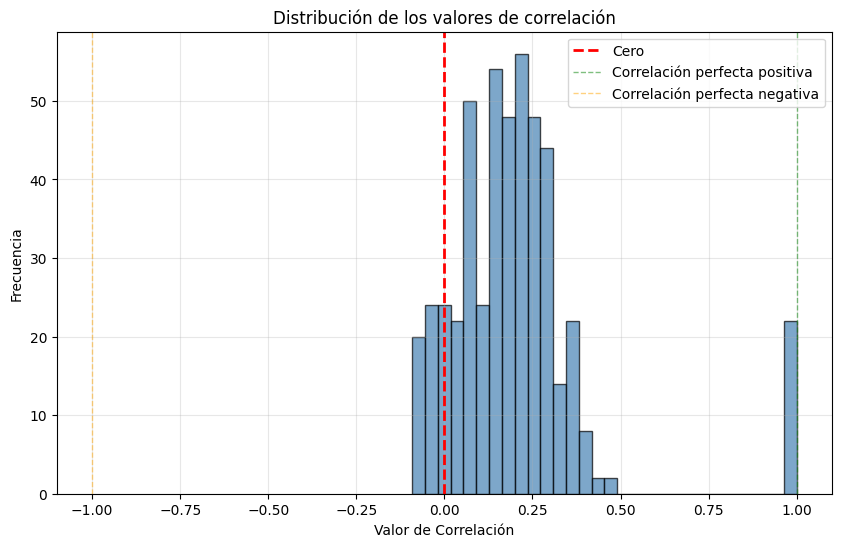

In [77]:
#para la matriz de correlación
matriz_correlacion = rendimientos_filtrado.corr()

matriz_correlacion

correlacion_plana = matriz_correlacion.values.flatten()

plt.figure(figsize=(10, 6))
plt.hist(correlacion_plana, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
plt.xlabel('Valor de Correlación')
plt.ylabel('Frecuencia')
plt.title('Distribución de los valores de correlación')
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Cero')
plt.axvline(x=1, color='green', linestyle='--', linewidth=1, alpha=0.5, label='Correlación perfecta positiva')
plt.axvline(x=-1, color='orange', linestyle='--', linewidth=1, alpha=0.5, label='Correlación perfecta negativa')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [78]:
#en base a la grafica anterior tomemos a aquellas correlaciones entre el intervalo [0, 0.25) ademas agregaremos algo para la visualizacion
pares_corr = []
for i in range(len(matriz_correlacion)):
    for j in range(i+1, len(matriz_correlacion)):
        valor = matriz_correlacion.iloc[i, j]
        if 0 <= valor < 0.25:  # Rango [0, 0.25)
            pares_corr.append({
                'Activo 1': matriz_correlacion.index[i],
                'Activo 2': matriz_correlacion.columns[j],
                'Correlación': valor
            })

tabla_correlacion = pd.DataFrame(pares_corr).sort_values('Correlación', ascending=True)

# Mostrar la tabla
print("=== PARES ÚNICOS CON CORRELACIÓN EN [0, 0.25) (ordenado de menor a mayor) ===\n")
print(tabla_correlacion.to_string(index=False))


=== PARES ÚNICOS CON CORRELACIÓN EN [0, 0.25) (ordenado de menor a mayor) ===

     Activo 1      Activo 2  Correlación
       ARA.MX       AMXB.MX     0.006858
       ARA.MX    GENTERA.MX     0.010187
       ARA.MX         AC.MX     0.010433
  CYDSASAA.MX TLEVISACPO.MX     0.015770
   PE&OLES.MX        ARA.MX     0.020843
TLEVISACPO.MX   FEMSAUBD.MX     0.023651
  CYDSASAA.MX      ALSEA.MX     0.034511
   PE&OLES.MX   FEMSAUBD.MX     0.039118
  CYDSASAA.MX        ARA.MX     0.041759
   GENTERA.MX   FEMSAUBD.MX     0.041930
  CYDSASAA.MX   GCARSOA1.MX     0.042234
  GFNORTEO.MX LIVEPOLC-1.MX     0.046961
   KIMBERA.MX LIVEPOLC-1.MX     0.047457
TLEVISACPO.MX     PINFRA.MX     0.048065
  CYDSASAA.MX       AMXB.MX     0.052431
    VOLARA.MX   FEMSAUBD.MX     0.054739
  GMEXICOB.MX        ARA.MX     0.057553
  CYDSASAA.MX    GENTERA.MX     0.057556
  CYDSASAA.MX    BBAJIOO.MX     0.061648
       GCC.MX    SIGMAFA.MX     0.061772
   SIGMAFA.MX LIVEPOLC-1.MX     0.062026
  CYDSASAA.MX     P

de aqui podemos ver que las siguientes acciones tienen un nivel bajo de correlación, lo cual es importante ver para poder diversificar nuestra cartera de inversión

In [79]:
# este codigo es para visualización de las acciones
filas_moradas = [0, 2, 26, 31, 37, 49, 23]
filas_moradas_filtradas = [i for i in filas_moradas if i < 50]

for pos in filas_moradas_filtradas:
    if pos < len(tabla_correlacion.head(50)):
        idx_real = tabla_correlacion.head(50).index[pos]

def resaltar_filas(df):
    estilos = pd.DataFrame("", index=df.index, columns=df.columns)
    
    for idx_pos in filas_moradas_filtradas:
        if idx_pos < len(df):
            idx_real = df.index[idx_pos]
            estilos.loc[idx_real, :] = "background-color: #c8a2c8; font-weight: bold"  # Morado claro
    
    return estilos
tabla_correlacion_estilizada = tabla_correlacion.head(50).style.apply(resaltar_filas, axis=None)
display(tabla_correlacion_estilizada)

,Activo 1,Activo 2,Correlación
75,ARA.MX,AMXB.MX,0.006858
76,ARA.MX,GENTERA.MX,0.010187
78,ARA.MX,AC.MX,0.010433
45,CYDSASAA.MX,TLEVISACPO.MX,0.015770
3,PE&OLES.MX,ARA.MX,0.020843
96,TLEVISACPO.MX,FEMSAUBD.MX,0.023651
49,CYDSASAA.MX,ALSEA.MX,0.034511
15,PE&OLES.MX,FEMSAUBD.MX,0.039118
43,CYDSASAA.MX,ARA.MX,0.041759
116,GENTERA.MX,FEMSAUBD.MX,0.041930


## Carteras óptimas identificadas

De todo lo anterior podemos ver que aquellas **acciones óptimas** y aquellas **carteras posibles** son:

| # | Cartera (Par de acciones) |
|---|---------------------------|
| 1 | ARA.MX / AMXB.MX |
| 2 | ARA.MX / AC.MX |
| 3 | LIVEPOLC-1.MX / FEMSAUBD.MX |
| 4 | GCC.MX / LIVEPOLC-1.MX |
| 5 | AMXB.MX / LIVEPOLC-1.MX |
| 6 | AC.MX / LIVEPOLC-1.MX |
| 7 | CEMEXCPO.MX / LIVEPOLC-1.MX |

De aqui tomamos los siguientes datos importantes

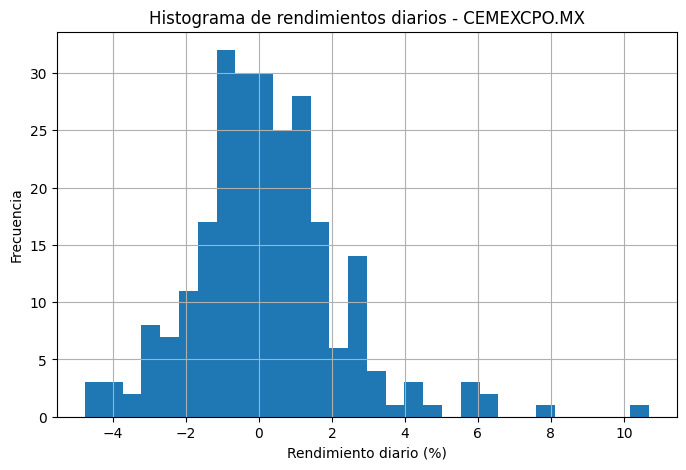

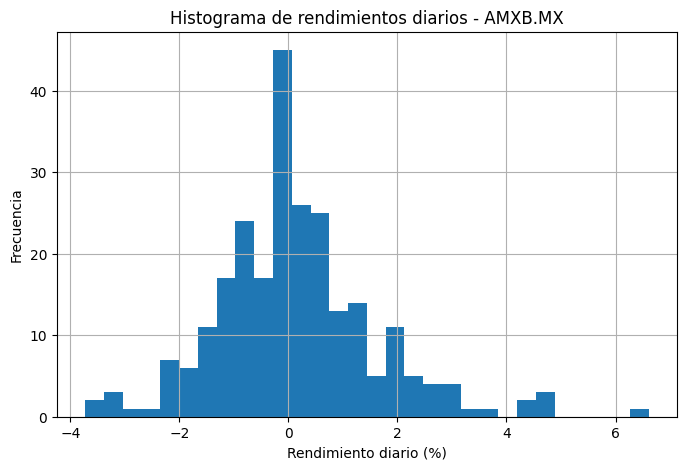

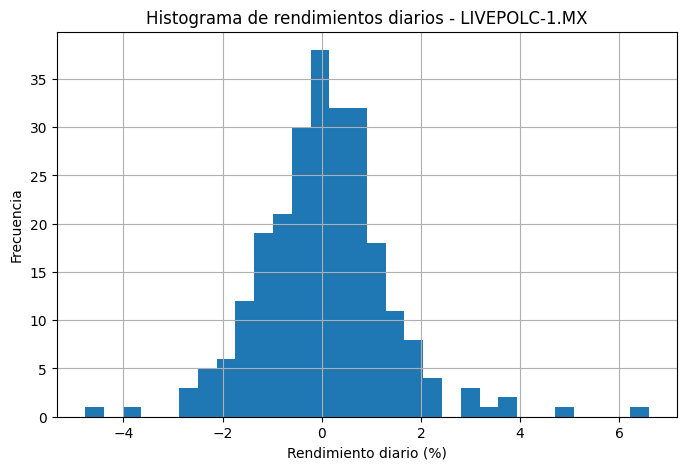

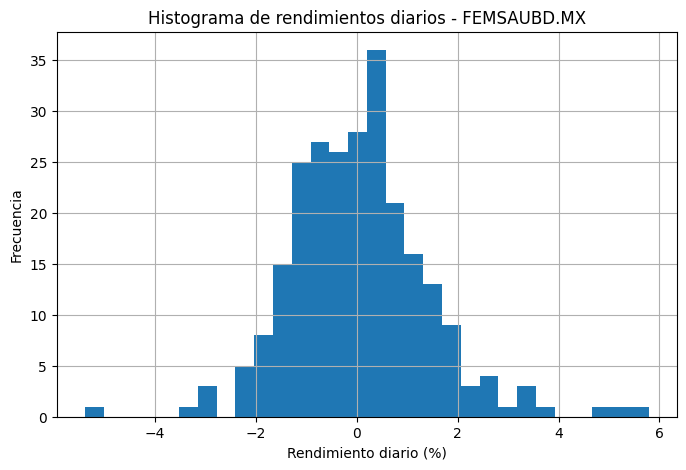

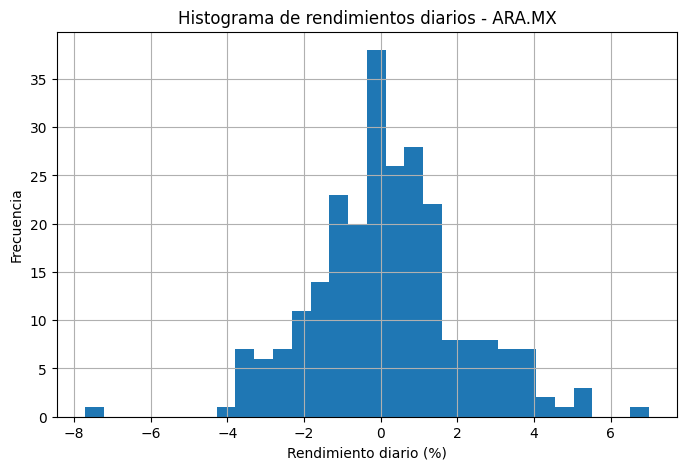

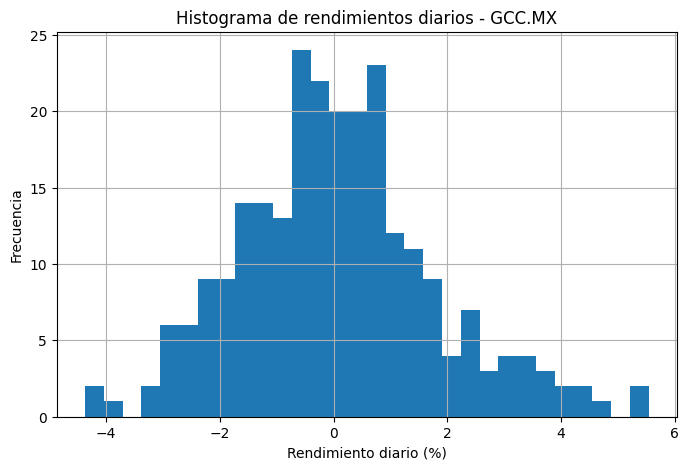

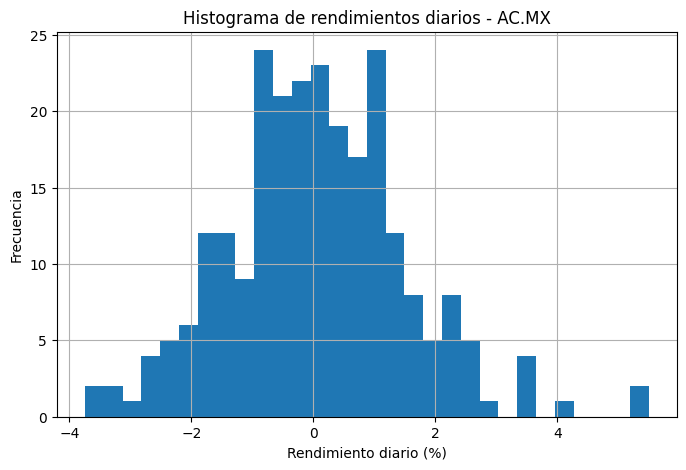

In [80]:
# Histogramas de rendimientos diarios de las acciones seleccionadas

acciones_histogramas = [
    "CEMEXCPO.MX",
    "AMXB.MX",
    "LIVEPOLC-1.MX",
    "FEMSAUBD.MX",
    "ARA.MX",
    "GCC.MX",
    "AC.MX"
]

for accion in acciones_histogramas:

    datos = rendimientos[accion].dropna()

    plt.figure(figsize=(8, 5))
    plt.hist(datos, bins=30)

    plt.title(f"Histograma de rendimientos diarios - {accion}")
    plt.xlabel("Rendimiento diario (%)")
    plt.ylabel("Frecuencia")
    plt.grid(True)

    plt.show()

In [81]:
# Columnas y renglones
columnas_seleccionadas = ['Media', 'Desviacion_Estandar', 'Varianza']
renglones_seleccionados = ['CEMEXCPO.MX', 'AMXB.MX', 'LIVEPOLC-1.MX', 'FEMSAUBD.MX', 'ARA.MX', 'GCC.MX', 'AC.MX']

estadisticas_seleccion = estadisticas_A1.loc[renglones_seleccionados, columnas_seleccionadas]
estadisticas_seleccion

,Media,Desviacion_Estandar,Varianza
CEMEXCPO.MX,0.214580,2.052619,4.213244
AMXB.MX,0.144346,1.479650,2.189364
LIVEPOLC-1.MX,0.054310,1.308706,1.712712
FEMSAUBD.MX,0.051880,1.396050,1.948957
ARA.MX,0.175467,1.946153,3.787510
GCC.MX,0.073482,1.734439,3.008278
AC.MX,0.054574,1.477361,2.182595


## Comparación de portafolios de dos activos con pesos diferentes

Para esto debemos considerar las siguientes fórmulas:

1. **Rendimiento esperado del portafolio**  
   $$ E(R_p) = w_1 E(R_1) + w_2 E(R_2) $$

2. **Varianza del portafolio**  
   Para un portafolio de 2 acciones, la varianza del portafolio se calcula así:  
   $$ \sigma_p^2 = w_1^2 \sigma_1^2 + w_2^2 \sigma_2^2 + 2w_1w_2 \text{Cov}(R_1, R_2) $$

3. **Riesgo del portafolio (Desviación estándar)**  
   $$ \sigma_p = \sqrt{\sigma_p^2} = \sqrt{\text{Var}(P)} $$

4. **Índice de Sharpe (Medida de performance)**  
   La medición del performance, o del resultado o rendimiento, nos permite obtener una medida de la calidad de gestión de las carteras formadas por títulos financieros en base a la rentabilidad y al riesgo. Además, nos facilita la comparación entre ellas mediante medidas homogéneas.  

   La medida de performance que nos hemos planteado inicialmente es el **índice de Sharpe (1966)**, cuya expresión es la siguiente:  
   $$ S_p = \frac{E_p - R_f}{\sigma_p} $$

   *Nota:* Algunas versiones del índice de Sharpe utilizan la desviación estándar ($\sigma_p$) en lugar de la varianza ($\sigma_p^2$).

In [82]:

# Tasa libre de riesgo desde estadisticas_A1
rf_bono_m10 = estadisticas_A1.loc["RF_BONO_M10", "Media"]

# Función para calcular rendimiento, varianza, riesgo y Sharpe para aplicarlo a nuestras acciones seleccionadas
def calcular_portafolio(nombre_portafolio, accion_1, accion_2, w1, w2):

    # Medias de las acciones
    media_1 = estadisticas_seleccion.loc[accion_1, "Media"]
    media_2 = estadisticas_seleccion.loc[accion_2, "Media"]

    # Rendimiento esperado del portafolio
    rendimiento_esperado = (w1 * media_1) + (w2 * media_2)

    # Varianzas de las acciones
    varianza_1 = estadisticas_seleccion.loc[accion_1, "Varianza"]
    varianza_2 = estadisticas_seleccion.loc[accion_2, "Varianza"]

    # Covarianza entre las acciones
    covarianza_12 = matriz_covarianza.loc[accion_1, accion_2]

    # Varianza del portafolio
    varianza_portafolio = (
        (w1 ** 2) * varianza_1
        + (w2 ** 2) * varianza_2
        + 2 * w1 * w2 * covarianza_12
    )

    # Riesgo del portafolio
    riesgo_portafolio = varianza_portafolio ** 0.5

    # Índice de Sharpe
    sharpe_portafolio = (
        rendimiento_esperado - rf_bono_m10
    ) / riesgo_portafolio

    return {
        "Portafolio": nombre_portafolio,
        "Acción 1": accion_1,
        "Acción 2": accion_2,
        "Peso Acción 1": w1,
        "Peso Acción 2": w2,
        "Rendimiento Esperado": rendimiento_esperado,
        "Varianza": varianza_portafolio,
        "Riesgo": riesgo_portafolio,
        "Tasa Libre de Riesgo": rf_bono_m10,
        "Índice de Sharpe": sharpe_portafolio
    }



# Definimos los 7 portafolios con mismos pesos para empezar
portafolios = [
    ("A", "ARA.MX", "AMXB.MX", 0.50, 0.50),
    ("B", "GCC.MX", "LIVEPOLC-1.MX", 0.50, 0.50),
    ("C", "AMXB.MX", "LIVEPOLC-1.MX", 0.50, 0.50),
    ("D", "AC.MX", "LIVEPOLC-1.MX", 0.50, 0.50),
    ("E", "CEMEXCPO.MX", "LIVEPOLC-1.MX", 0.50, 0.50),
    ("F", "LIVEPOLC-1.MX", "FEMSAUBD.MX", 0.50, 0.50),
    ("G", "ARA.MX", "AC.MX", 0.50, 0.50)
]


# Calcular resultados de todos los portafolios

resultados_portafolios = []

for nombre, accion_1, accion_2, w1, w2 in portafolios:

    resultado = calcular_portafolio(
        nombre,
        accion_1,
        accion_2,
        w1,
        w2
    )

    resultados_portafolios.append(resultado)

#para visualizar los resultados de los portafolios en un cuadro comparativo
cuadro_comparativo = pd.DataFrame(resultados_portafolios)

cuadro_comparativo

,Portafolio,Acción 1,Acción 2,Peso Acción 1,Peso Acción 2,Rendimiento Esperado,Varianza,Riesgo,Tasa Libre de Riesgo,Índice de Sharpe
0,A,ARA.MX,AMXB.MX,0.5,0.5,0.159907,1.504093,1.226415,0.033467,0.103097
1,B,GCC.MX,LIVEPOLC-1.MX,0.5,0.5,0.063896,1.261200,1.123032,0.033467,0.027096
2,C,AMXB.MX,LIVEPOLC-1.MX,0.5,0.5,0.099328,1.050888,1.025128,0.033467,0.064247
3,D,AC.MX,LIVEPOLC-1.MX,0.5,0.5,0.054442,1.059399,1.029271,0.033467,0.020379
4,E,CEMEXCPO.MX,LIVEPOLC-1.MX,0.5,0.5,0.134445,1.640018,1.280632,0.033467,0.078850
5,F,LIVEPOLC-1.MX,FEMSAUBD.MX,0.5,0.5,0.053095,0.977678,0.988776,0.033467,0.019851
6,G,ARA.MX,AC.MX,0.5,0.5,0.115021,1.507524,1.227813,0.033467,0.066422


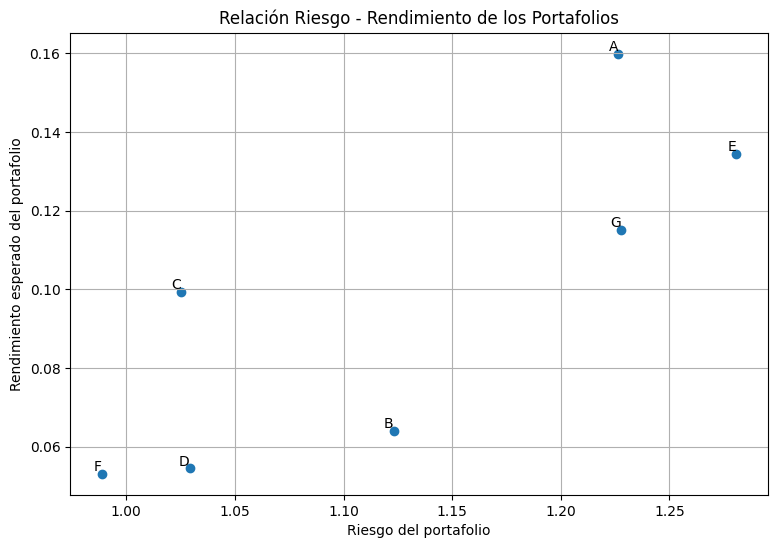

In [83]:
# codigo para visualizar
plt.figure(figsize=(9, 6))

plt.scatter(
    cuadro_comparativo["Riesgo"],
    cuadro_comparativo["Rendimiento Esperado"]
)

# Agregar etiqueta a cada punto: A, B, C, D, etc.
for i in range(len(cuadro_comparativo)):
    plt.text(
        cuadro_comparativo["Riesgo"].iloc[i],
        cuadro_comparativo["Rendimiento Esperado"].iloc[i],
        cuadro_comparativo["Portafolio"].iloc[i],
        fontsize=10,
        ha="right",
        va="bottom"
    )

# Títulos y etiquetas
plt.title("Relación Riesgo - Rendimiento de los Portafolios")
plt.xlabel("Riesgo del portafolio")
plt.ylabel("Rendimiento esperado del portafolio")

# Cuadrícula
plt.grid(True)

# Mostrar gráfica
plt.show()

Sin embargo, hay que buscar los **pesos óptimos**. Para eso debe cumplir diferentes criterios:

- Primero, los pesos deben **sumar 1**.
- Además, es importante que el **rendimiento suba** y el **riesgo baje**.

Para esto, lo ideal sería optimizar el **índice S**, ya que:

$$ 
S = \frac{\text{Rendimiento excedente}}{\text{Riesgo}} 
$$

Se tiene que el índice es **inversamente proporcional al riesgo**, es decir:

> Si el riesgo baja → el rendimiento sube → el índice S también lo hace.

Por lo tanto, tomando estas consideraciones, **hacemos la optimización**.

In [84]:
# Optimización de pesos para portafolios de dos activos
# Maximizando el Índice de Sharpe

# Tasa libre de riesgo desde estadisticas_A1
rf_bono_m10 = estadisticas_A1.loc["RF_BONO_M10", "Media"]

def calcular_metricas_portafolio(accion_1, accion_2, w1, w2):

    media_1 = estadisticas_seleccion.loc[accion_1, "Media"]
    media_2 = estadisticas_seleccion.loc[accion_2, "Media"]

    varianza_1 = estadisticas_seleccion.loc[accion_1, "Varianza"]
    varianza_2 = estadisticas_seleccion.loc[accion_2, "Varianza"]

    covarianza_12 = matriz_covarianza.loc[accion_1, accion_2]

    rendimiento_esperado = (w1 * media_1) + (w2 * media_2)

    varianza_portafolio = (
        (w1 ** 2) * varianza_1
        + (w2 ** 2) * varianza_2
        + 2 * w1 * w2 * covarianza_12
    )

    riesgo_portafolio = varianza_portafolio ** 0.5

    sharpe_portafolio = (
        rendimiento_esperado - rf_bono_m10
    ) / riesgo_portafolio

    return rendimiento_esperado, varianza_portafolio, riesgo_portafolio, sharpe_portafolio

#en esta parte el codigo es rescatado ya que estamos buscando un equivalente la funcion "solver" de excel para optimizar los pesos de cada portafolio
def funcion_objetivo(pesos, accion_1, accion_2):

    w1 = pesos[0]
    w2 = pesos[1]

    rendimiento, varianza, riesgo, sharpe = calcular_metricas_portafolio(
        accion_1,
        accion_2,
        w1,
        w2
    )

    return -sharpe

portafolios = [
    ("A", "ARA.MX", "AMXB.MX"),
    ("B", "GCC.MX", "LIVEPOLC-1.MX"),
    ("C", "AMXB.MX", "LIVEPOLC-1.MX"),
    ("D", "AC.MX", "LIVEPOLC-1.MX"),
    ("E", "CEMEXCPO.MX", "LIVEPOLC-1.MX"),
    ("F", "LIVEPOLC-1.MX", "FEMSAUBD.MX"),
    ("G", "ARA.MX", "AC.MX")
]


# ============================================================
# Restricciones
# ============================================================

# Los pesos deben sumar 1
restricciones = (
    {
        "type": "eq",
        "fun": lambda pesos: pesos[0] + pesos[1] - 1
    },
)

# Cada peso debe estar entre 0 y 1
limites = (
    (0, 1),
    (0, 1)
)

# Pesos iniciales
pesos_iniciales = [0.50, 0.50]


# ============================================================
# Optimizar cada portafolio
# ============================================================

resultados_optimizados = []

for nombre, accion_1, accion_2 in portafolios:

    resultado = minimize(
        funcion_objetivo,
        pesos_iniciales,
        args=(accion_1, accion_2),
        method="SLSQP",
        bounds=limites,
        constraints=restricciones
    )

    w1_optimo = resultado.x[0]
    w2_optimo = resultado.x[1]

    rendimiento, varianza, riesgo, sharpe = calcular_metricas_portafolio(
        accion_1,
        accion_2,
        w1_optimo,
        w2_optimo
    )

    resultados_optimizados.append({
        "Portafolio": nombre,
        "Acción 1": accion_1,
        "Acción 2": accion_2,
        "Peso óptimo Acción 1": w1_optimo,
        "Peso óptimo Acción 2": w2_optimo,
        "Rendimiento Esperado": rendimiento,
        "Varianza": varianza,
        "Riesgo": riesgo,
        "Tasa Libre de Riesgo": rf_bono_m10,
        "Índice de Sharpe": sharpe
    })

cuadro_optimizacion = pd.DataFrame(resultados_optimizados)

cuadro_optimizacion = cuadro_optimizacion.sort_values(
    by="Índice de Sharpe",
    ascending=False
)

cuadro_optimizacion

,Portafolio,Acción 1,Acción 2,Peso óptimo Acción 1,Peso óptimo Acción 2,Rendimiento Esperado,Varianza,Riesgo,Tasa Libre de Riesgo,Índice de Sharpe
0,A,ARA.MX,AMXB.MX,0.424937,0.575063,0.157571,1.417585,1.190624,0.033467,0.104234
4,E,CEMEXCPO.MX,LIVEPOLC-1.MX,0.906138,0.093862,0.199536,3.528455,1.878418,0.033467,0.088409
2,C,AMXB.MX,LIVEPOLC-1.MX,0.862624,0.137376,0.131977,1.697197,1.302765,0.033467,0.075617
6,G,ARA.MX,AC.MX,0.800420,0.199580,0.151339,2.523075,1.588419,0.033467,0.074208
1,B,GCC.MX,LIVEPOLC-1.MX,0.535332,0.464668,0.064574,1.312465,1.145629,0.033467,0.027153
3,D,AC.MX,LIVEPOLC-1.MX,0.437463,0.562537,0.054426,1.043909,1.021719,0.033467,0.020514
5,F,LIVEPOLC-1.MX,FEMSAUBD.MX,0.569764,0.430236,0.053265,0.977806,0.988841,0.033467,0.020022


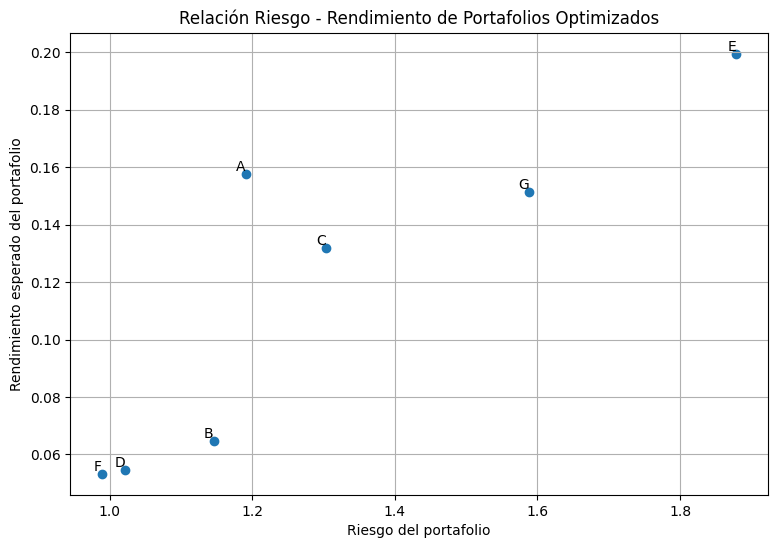

In [85]:
# ============================================================
# Gráfica Riesgo - Rendimiento de portafolios optimizados
# ============================================================


plt.figure(figsize=(9, 6))

plt.scatter(
    cuadro_optimizacion["Riesgo"],
    cuadro_optimizacion["Rendimiento Esperado"]
)

for i in range(len(cuadro_optimizacion)):
    plt.text(
        cuadro_optimizacion["Riesgo"].iloc[i],
        cuadro_optimizacion["Rendimiento Esperado"].iloc[i],
        cuadro_optimizacion["Portafolio"].iloc[i],
        fontsize=10,
        ha="right",
        va="bottom"
    )

plt.title("Relación Riesgo - Rendimiento de Portafolios Optimizados")
plt.xlabel("Riesgo del portafolio")
plt.ylabel("Rendimiento esperado del portafolio")
plt.grid(True)
plt.show()

Ahora el siguiente paso es obtener nuestro portafolio con nuestras 7 acciones seleccionadas 
## PORTAFOLIO CON 7 ACCIONES
para eso necesitaremos ayuda de las siguientes funciones:

## Formulario para optimización de portafolios

### 1. Rendimiento esperado del portafolio

El rendimiento esperado del portafolio se calcula como el producto del vector de pesos y el vector de rendimientos medios:

$$ E(R_p) = w \cdot r^T $$

Donde:
- $w$: vector de pesos de cada activo
- $r^T$: vector transpuesto de rendimientos medios

### 2. Riesgo del portafolio

El riesgo del portafolio se mide como la raíz cuadrada de la varianza:

$$ \text{RI}(P) = \sqrt{w \Sigma w^T} $$

Donde:
- $w$: vector de pesos
- $\Sigma$: matriz de covarianza
- $w^T$: vector transpuesto de pesos

### 3. Índice de Sharpe

El índice de Sharpe mide el rendimiento excedente por unidad de riesgo:

$$ S(P) = \frac{E(R_p) - R_f}{\text{RI}(P)} $$

Donde:
- $E(R_p)$: rendimiento esperado del portafolio
- $R_f$: tasa libre de riesgo
- $\text{RI}(P)$: riesgo del portafolio

### 4. Matriz de covarianza

La matriz de covarianza $\Sigma$ contiene las varianzas y covarianzas de los activos:

$$ 
\Sigma = 
\begin{bmatrix}
\sigma_1^2 & \sigma_{12} & \cdots & \sigma_{1n} \\
\sigma_{21} & \sigma_2^2 & \cdots & \sigma_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
\sigma_{n1} & \sigma_{n2} & \cdots & \sigma_n^2
\end{bmatrix}
$$

Donde:
- $\sigma_i^2$: varianza del activo $i$ (diagonal)
- $\sigma_{ij}$: covarianza entre el activo $i$ y el activo $j$ (fuera de la diagonal)

### 5. Vectores de pesos y rendimientos

Para un portafolio de 7 activos, los vectores se definen como:

$$ w = [w_1, w_2, \dots, w_7] $$

$$ r = [\bar{R}_1, \bar{R}_2, \dots, \bar{R}_7] $$

Donde:
- $w_i$: peso del activo $i$ en el portafolio ($\sum w_i = 1$)
- $\bar{R}_i$: rendimiento medio del activo $i$

Adelante tenemos cuadros con la información obtenida para y apartir de estas formulas:

In [86]:
# Portafolio de 7 acciones
# Cálculo matricial de E(Rp), Var(P), RI(P) e Índice S

#Definimos las acciones del portafolio

acciones_portafolio = [
    "CEMEXCPO.MX",
    "AMXB.MX",
    "LIVEPOLC-1.MX",
    "FEMSAUBD.MX",
    "ARA.MX",
    "GCC.MX",
    "AC.MX"
]

# Definimos el vector de pesos w con unos primeros valores preliminares
w = np.array([
    0.20,  # CEMEXCPO.MX
    0.15,  # AMXB.MX
    0.15,  # LIVEPOLC-1.MX
    0.10,  # FEMSAUBD.MX
    0.20,  # ARA.MX
    0.10,  # GCC.MX
    0.10   # AC.MX
])

# ============================================================
# Definir el vector de rendimientos medios r
# ============================================================

r = estadisticas_seleccion.loc[
    acciones_portafolio,
    "Media"
].values

# ============================================================
# Definir la matriz de covarianzas Sigma
# ============================================================

sigma = matriz_covarianza.loc[
    acciones_portafolio,
    acciones_portafolio
]

# ============================================================
# Calcular el rendimiento esperado del portafolio
# E(Rp) = w · r
# ============================================================

rendimiento_esperado_portafolio = w @ r

# ============================================================
# 6. Calcular la varianza del portafolio
# Var(P) = w · Sigma · w^T
# ============================================================

varianza_portafolio = w @ sigma.values @ w.T

# ============================================================
# 7. Calcular el riesgo del portafolio
# RI(P) = sqrt(Var(P))
# ============================================================

riesgo_portafolio = varianza_portafolio ** 0.5

# ============================================================
# 8. Calcular el índice S
# S(P) = (E(Rp) - Rf) / RI(P)
# ============================================================

rf_bono_m10 = estadisticas_A1.loc["RF_BONO_M10", "Media"]

indice_s = (
    rendimiento_esperado_portafolio - rf_bono_m10
) / riesgo_portafolio

# ============================================================
# 9. Crear DataFrame con los pesos por acción
# ============================================================

pesos_portafolio = pd.DataFrame({
    "Acción": acciones_portafolio,
    "Peso": w,
    "Media": r
})

# ============================================================
# 10. Crear DataFrame con resultados del portafolio
# ============================================================

resultados_portafolio = pd.DataFrame({
    "Concepto": [
        "Suma de pesos",
        "Rendimiento esperado",
        "Varianza",
        "Riesgo",
        "Tasa libre de riesgo",
        "Índice S"
    ],
    "Resultado": [
        w.sum(),
        rendimiento_esperado_portafolio,
        varianza_portafolio,
        riesgo_portafolio,
        rf_bono_m10,
        indice_s
    ]
})

# ============================================================
# 11. Mostrar resultados
# ============================================================

display(pesos_portafolio)
display(sigma.round(4))
display(resultados_portafolio)

,Acción,Peso,Media
0,CEMEXCPO.MX,0.20,0.214580
1,AMXB.MX,0.15,0.144346
2,LIVEPOLC-1.MX,0.15,0.054310
3,FEMSAUBD.MX,0.10,0.051880
4,ARA.MX,0.20,0.175467
5,GCC.MX,0.10,0.073482
6,AC.MX,0.10,0.054574


,CEMEXCPO.MX,AMXB.MX,LIVEPOLC-1.MX,FEMSAUBD.MX,ARA.MX,GCC.MX,AC.MX
CEMEXCPO.MX,4.2132,1.0069,0.3171,0.7027,-0.1092,1.4596,0.8537
AMXB.MX,1.0069,2.1894,0.1507,0.6788,0.0197,0.6351,0.6584
LIVEPOLC-1.MX,0.3171,0.1507,1.7127,0.1245,0.2392,0.1619,0.1711
FEMSAUBD.MX,0.7027,0.6788,0.1245,1.9490,-0.1500,0.6647,0.7236
ARA.MX,-0.1092,0.0197,0.2392,-0.1500,3.7875,-0.0396,0.0300
GCC.MX,1.4596,0.6351,0.1619,0.6647,-0.0396,3.0083,0.6299
AC.MX,0.8537,0.6584,0.1711,0.7236,0.0300,0.6299,2.1826


,Concepto,Resultado
0,Suma de pesos,1.000000
1,Rendimiento esperado,0.125802
2,Varianza,0.799761
3,Riesgo,0.894293
4,Tasa libre de riesgo,0.033467
5,Índice S,0.103249


el siguiente paso es optimizar para obtener los pesos ideales que aumente los rendimientos y siguiendo la logica anterior buscaremos maximizar el indice s

In [87]:
# Optimización del portafolio de 7 acciones
# Maximizando el Índice S / Sharpe

acciones_portafolio = [
    "CEMEXCPO.MX",
    "AMXB.MX",
    "LIVEPOLC-1.MX",
    "FEMSAUBD.MX",
    "ARA.MX",
    "GCC.MX",
    "AC.MX"
]

# Definir vector de rendimientos medios r

r = estadisticas_seleccion.loc[
    acciones_portafolio,
    "Media"
].values

# Definir matriz de covarianzas Sigma

sigma = matriz_covarianza.loc[
    acciones_portafolio,
    acciones_portafolio
].values

# Tasa libre de riesgo

rf_bono_m10 = estadisticas_A1.loc["RF_BONO_M10", "Media"]

# Función para calcular métricas del portafolio

def calcular_metricas(w):

    # Rendimiento esperado
    rendimiento_esperado = w @ r

    # Varianza
    varianza = w @ sigma @ w.T

    # Riesgo
    riesgo = varianza ** 0.5

    # Índice S / Sharpe
    indice_s = (rendimiento_esperado - rf_bono_m10) / riesgo

    return rendimiento_esperado, varianza, riesgo, indice_s

# Como queremos maximizar S, minimizamos -S

def funcion_objetivo(w):

    rendimiento_esperado, varianza, riesgo, indice_s = calcular_metricas(w)

    return -indice_s

# Restricciones

# La suma de los pesos debe ser igual a 1
restricciones = (
    {
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1
    },
)

# Cada peso debe estar entre 0 y 1
limites = tuple(
    (0, 1) for accion in acciones_portafolio
)

# Pesos iniciales iguales
w_inicial = np.repeat(
    1 / len(acciones_portafolio),
    len(acciones_portafolio)
)

#  Optimización

resultado_optimizacion = minimize(
    funcion_objetivo,
    w_inicial,
    method="SLSQP",
    bounds=limites,
    constraints=restricciones
)

# Pesos óptimos
w_optimo = resultado_optimizacion.x

#  Calcular resultados con pesos óptimos

rendimiento_optimo, varianza_optima, riesgo_optimo, indice_s_optimo = calcular_metricas(w_optimo)

pesos_optimos = pd.DataFrame({
    "Acción": acciones_portafolio,
    "Peso óptimo": w_optimo,
    "Media": r
})

resultados_optimos = pd.DataFrame({
    "Concepto": [
        "Suma de pesos",
        "Rendimiento esperado",
        "Varianza",
        "Riesgo",
        "Tasa libre de riesgo",
        "Índice S"
    ],
    "Resultado": [
        w_optimo.sum(),
        rendimiento_optimo,
        varianza_optima,
        riesgo_optimo,
        rf_bono_m10,
        indice_s_optimo
    ]
})

display(pesos_optimos)
display(resultados_optimos)

,Acción,Peso óptimo,Media
0,CEMEXCPO.MX,3.335953e-01,0.214580
1,AMXB.MX,3.104080e-01,0.144346
2,LIVEPOLC-1.MX,1.050955e-16,0.054310
3,FEMSAUBD.MX,4.043351e-17,0.051880
4,ARA.MX,3.559968e-01,0.175467
5,GCC.MX,0.000000e+00,0.073482
6,AC.MX,0.000000e+00,0.054574


,Concepto,Resultado
0,Suma de pesos,1.000000
1,Rendimiento esperado,0.178855
2,Varianza,1.346785
3,Riesgo,1.160511
4,Tasa libre de riesgo,0.033467
5,Índice S,0.125279


Ahora este es un caso particular de todas los portafolios que podriamos contruir, ahora vamos a hacer 2500 simulaciones y buscaremos la frontera eficiente:

In [88]:
# Simulación de 2,500 portafolios y frontera eficiente

acciones_portafolio = [
    "CEMEXCPO.MX",
    "AMXB.MX",
    "LIVEPOLC-1.MX",
    "FEMSAUBD.MX",
    "ARA.MX",
    "GCC.MX",
    "AC.MX"
]

# Definir vector de rendimientos medios r

r = estadisticas_seleccion.loc[
    acciones_portafolio,
    "Media"
].values

# Definir matriz de covarianzas Sigma

sigma = matriz_covarianza.loc[
    acciones_portafolio,
    acciones_portafolio
].values

# Tasa libre de riesgo

rf_bono_m10 = estadisticas_A1.loc["RF_BONO_M10", "Media"]

# Número de simulaciones

n_simulaciones = 2500
n_acciones = len(acciones_portafolio)

# Listas para guardar resultados

resultados_simulacion = []

# Simular portafolios aleatorios

for i in range(n_simulaciones):

    # Generar pesos aleatorios
    w = np.random.random(n_acciones)

    # Normalizar pesos para que sumen 1
    w = w / np.sum(w)

    # Rendimiento esperado del portafolio
    rendimiento_esperado = w @ r

    # Varianza del portafolio
    varianza = w @ sigma @ w.T

    # Riesgo del portafolio
    riesgo = varianza ** 0.5

    # Índice S / Sharpe
    indice_s = (rendimiento_esperado - rf_bono_m10) / riesgo

    # Guardar resultados
    resultado = {
        "Simulación": i + 1,
        "Rendimiento Esperado": rendimiento_esperado,
        "Varianza": varianza,
        "Riesgo": riesgo,
        "Índice S": indice_s
    }

    # Guardar pesos de cada acción
    for j, accion in enumerate(acciones_portafolio):
        resultado[f"Peso {accion}"] = w[j]

    resultados_simulacion.append(resultado)

df_simulaciones = pd.DataFrame(resultados_simulacion)

df_simulaciones.head()

,Simulación,Rendimiento Esperado,Varianza,Riesgo,Índice S,Peso CEMEXCPO.MX,Peso AMXB.MX,Peso LIVEPOLC-1.MX,Peso FEMSAUBD.MX,Peso ARA.MX,Peso GCC.MX,Peso AC.MX
0,1,0.121784,0.877395,0.936694,0.094287,0.246439,0.136724,0.125505,0.159166,0.124129,0.050787,0.157250
1,2,0.111590,0.693194,0.832583,0.093833,0.128728,0.119861,0.213223,0.140459,0.209647,0.039590,0.148492
2,3,0.118405,0.825046,0.908320,0.093512,0.173802,0.164245,0.291326,0.020282,0.146916,0.192916,0.010514
3,4,0.096736,0.848630,0.921211,0.068681,0.170256,0.047372,0.323626,0.018961,0.059324,0.192076,0.188386
4,5,0.111388,1.054837,1.027053,0.075869,0.211922,0.210147,0.132359,0.230843,0.007496,0.200458,0.006776


In [89]:
# Portafolio con mayor Índice S

portafolio_max_sharpe = df_simulaciones.loc[
    df_simulaciones["Índice S"].idxmax()
]
# Portafolio con menor riesgo

portafolio_min_riesgo = df_simulaciones.loc[
    df_simulaciones["Riesgo"].idxmin()
]


## VEAMOS LOS RESULTADOS

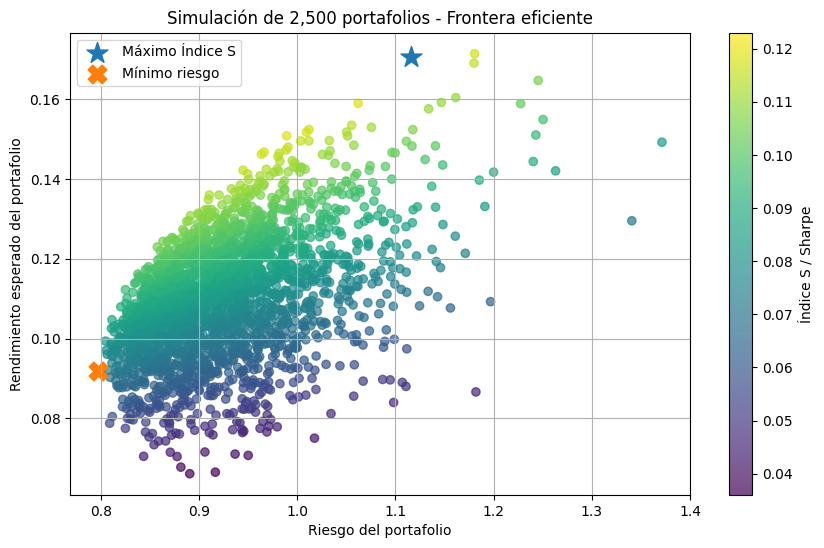

In [90]:
#Graficar Riesgo vs Rendimiento Esperado

plt.figure(figsize=(10, 6))

plt.scatter(
    df_simulaciones["Riesgo"],
    df_simulaciones["Rendimiento Esperado"],
    c=df_simulaciones["Índice S"],
    cmap="viridis",
    alpha=0.7
)

plt.colorbar(label="Índice S / Sharpe")

# Portafolio con mayor Índice S
plt.scatter(
    portafolio_max_sharpe["Riesgo"],
    portafolio_max_sharpe["Rendimiento Esperado"],
    marker="*",
    s=250,
    label="Máximo Índice S"
)

# Portafolio con menor riesgo
plt.scatter(
    portafolio_min_riesgo["Riesgo"],
    portafolio_min_riesgo["Rendimiento Esperado"],
    marker="X",
    s=180,
    label="Mínimo riesgo"
)

plt.title("Simulación de 2,500 portafolios - Frontera eficiente")
plt.xlabel("Riesgo del portafolio")
plt.ylabel("Rendimiento esperado del portafolio")
plt.legend()
plt.grid(True)
plt.show()

In [91]:

resumen_portafolios = pd.DataFrame([
    portafolio_max_sharpe,
    portafolio_min_riesgo
])

resumen_portafolios.index = [
    "Portafolio con máximo Índice S",
    "Portafolio con mínimo riesgo"
]

resumen_portafolios

,Simulación,Rendimiento Esperado,Varianza,Riesgo,Índice S,Peso CEMEXCPO.MX,Peso AMXB.MX,Peso LIVEPOLC-1.MX,Peso FEMSAUBD.MX,Peso ARA.MX,Peso GCC.MX,Peso AC.MX
Portafolio con máximo Índice S,1308.0,0.170663,1.243912,1.115308,0.123012,0.331502,0.294336,0.014087,0.034843,0.299913,0.024508,0.000811
Portafolio con mínimo riesgo,187.0,0.091819,0.635931,0.797453,0.073174,0.023357,0.107394,0.262482,0.191008,0.182304,0.127536,0.105918


De aqui podemos ver que nuestro rendimiento esperado sube hasta un 0.16% y ademas tiene un riesgo minimo cerca del 1% y con una varianza baja cumpliendo con los requisitos de un portafolio de muy bajo riesgo
Ahora veamos si se invierten $15,000 a un año en un instrumento de bajo riesgo (en este caso Bono M10) cual es nuestra ganancia:

In [92]:

patrimonio_inicial = 15000

# Tasa anual del Bono M10
tasa_bono_m10_anual = 0.0937

# Valor final después de un año
valor_final_bono_m10 = patrimonio_inicial * (1 + tasa_bono_m10_anual)

# Ganancia obtenida
ganancia_bono_m10 = valor_final_bono_m10 - patrimonio_inicial

print("Patrimonio inicial:", patrimonio_inicial)
print("Tasa anual Bono M10:", tasa_bono_m10_anual * 100, "%")
print("Valor final después de un año:", valor_final_bono_m10)
print("Ganancia obtenida:", ganancia_bono_m10)

Patrimonio inicial: 15000
Tasa anual Bono M10: 9.370000000000001 %
Valor final después de un año: 16405.5
Ganancia obtenida: 1405.5


Ahora veamos el rendimiento si hacemos la inversion de los $15,000 a un año en nuestro portafolio optimo: 


In [93]:
# ============================================================
# Rendimiento después de un año en el portafolio óptimo
# Portafolio con máximo Índice S
# ============================================================

patrimonio_inicial = 15000

# Rendimiento esperado diario del portafolio con máximo Índice S
rendimiento_diario_portafolio = 0.148901 / 100

# Días bursátiles en un año
dias_bursatiles = 252

# Valor final después de un año
valor_final_portafolio = patrimonio_inicial * (
    1 + rendimiento_diario_portafolio
) ** dias_bursatiles

# Ganancia obtenida
ganancia_portafolio = valor_final_portafolio - patrimonio_inicial

# Rendimiento anual equivalente
rendimiento_anual_portafolio = (
    (1 + rendimiento_diario_portafolio) ** dias_bursatiles - 1
) * 100

print("Patrimonio inicial:", patrimonio_inicial)
print("Rendimiento diario esperado:", rendimiento_diario_portafolio * 100, "%")
print("Valor final después de un año:", valor_final_portafolio)
print("Ganancia obtenida:", ganancia_portafolio)
print("Rendimiento anual equivalente:", rendimiento_anual_portafolio, "%")

Patrimonio inicial: 15000
Rendimiento diario esperado: 0.148901 %
Valor final después de un año: 21823.811342107307
Ganancia obtenida: 6823.811342107307
Rendimiento anual equivalente: 45.49207561404871 %


Ahora equivalente con el indice IPC

In [94]:
# ============================================================
# Rendimiento después de un año invirtiendo en el índice IPC
# ============================================================

patrimonio_inicial = 15000

# Rendimiento diario promedio del IPC desde estadisticas_A1
rendimiento_diario_ipc = estadisticas_A1.loc["IPC", "Media"] / 100

# Días bursátiles en un año
dias_bursatiles = 252

# Valor final después de un año
valor_final_ipc = patrimonio_inicial * (
    1 + rendimiento_diario_ipc
) ** dias_bursatiles

# Ganancia obtenida
ganancia_ipc = valor_final_ipc - patrimonio_inicial

# Rendimiento anual equivalente
rendimiento_anual_ipc = (
    (1 + rendimiento_diario_ipc) ** dias_bursatiles - 1
) * 100

print("Patrimonio inicial:", patrimonio_inicial)
print("Rendimiento diario promedio del IPC:", rendimiento_diario_ipc * 100, "%")
print("Valor final después de un año:", valor_final_ipc)
print("Ganancia obtenida:", ganancia_ipc)
print("Rendimiento anual equivalente:", rendimiento_anual_ipc, "%")

Patrimonio inicial: 15000
Rendimiento diario promedio del IPC: 0.07211955032000307 %
Valor final después de un año: 17988.37946086616
Ganancia obtenida: 2988.379460866159
Rendimiento anual equivalente: 19.92252973910773 %


In [95]:
# ============================================================
# Cuadro comparativo de inversión de $15,000 a un año
# ============================================================

cuadro_inversion = pd.DataFrame({
    "Alternativa": [
        "Instrumento seguro: BONO_M10",
        "Índice IPC",
        "Portafolio con máximo Índice S"
    ],
    "Patrimonio inicial": [
        patrimonio_inicial,
        patrimonio_inicial,
        patrimonio_inicial
    ],
    "Valor final después de un año": [
        valor_final_bono_m10,
        valor_final_ipc,
        valor_final_portafolio
    ],
    "Ganancia obtenida": [
        ganancia_bono_m10,
        ganancia_ipc,
        ganancia_portafolio
    ],
    "Rendimiento anual": [
        tasa_bono_m10_anual * 100,
        rendimiento_anual_ipc,
        rendimiento_anual_portafolio
    ]
})

cuadro_inversion = cuadro_inversion.round(2)

cuadro_inversion

,Alternativa,Patrimonio inicial,Valor final después de un año,Ganancia obtenida,Rendimiento anual
0,Instrumento seguro: BONO_M10,15000,16405.50,1405.50,9.37
1,Índice IPC,15000,17988.38,2988.38,19.92
2,Portafolio con máximo Índice S,15000,21823.81,6823.81,45.49


## Conclusiones:
asi podemos ver que es mas conveniente invertir en nuestro portafolio generado ya que nos ofrece un mayor rendimiento anual y cumple con el objetivo de tener un riesgo bastante bajo, que es uno de requerimientos.